# 9. Atok cropping patterns (unsupervised)

Notebook 08 found that no method could identify carrot, cabbage or potato in a field it had not seen (best 22% correct, while the regional calendar alone got 33%). What did work was separating cropland from non-crop: on held-out blocks of NAMRIA land-use non-crop samples, 77-90% were recognised as non-crop, with built-up land the weak class (68-73%), and K-means on cycle features was the only stable clustering (ARI 0.99).

This notebook therefore maps things that do not need crop names:

1. Land activity: active cropland, perennial vegetation, bare/built or mixed
2. Cropping regimes: clusters of growth cycles
3. Cycles per year and main peak season, compared with the number of crops per year in the KML calendars
4. Growth phase on three dates in 2025

The regimes are not crops. The KML is only used to describe and check the results.

In [1]:
from pathlib import Path
import json
import os
import re
import warnings
import xml.etree.ElementTree as ET

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from IPython.display import display
from matplotlib.colors import ListedColormap
from pyproj import Transformer
from rasterio.features import geometry_mask
from rasterio.windows import Window, from_bounds
from scipy.signal import find_peaks
from shapely import transform as shapely_transform, union_all
from shapely.geometry import Polygon, mapping
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=RuntimeWarning)
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
settings_path = Path("settings.local.json")
local_settings = json.loads(settings_path.read_text()) if settings_path.exists() else {}
report_folder = Path(local_settings.get("report_root", "./sen4agrinet_work/inventory")).expanduser().resolve()
analysis_root = Path(local_settings.get("analysis_root", "./analysis")).expanduser().resolve()  # outputs of notebooks 07-10
# The shared THS-SENTINEL2 folder: set atok_imagery_root in settings.local.json to wherever it syncs on this machine.
IMAGERY_ROOT = Path(local_settings.get("atok_imagery_root", "")).expanduser()
KML_PATH = Path(local_settings.get("atok_kml_path", "./data/atok/atok_benguet.kml")).expanduser()
LANDUSE_PATH = Path(local_settings.get("atok_landuse_path", "./data/atok/elum2023_benguet.gpkg")).expanduser()  # NAMRIA ELUM 2023
OUTPUT = analysis_root / "atok" / "regimes"
FIGURES = OUTPUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
SHARED_CUBE = analysis_root / "atok" / "weak_labels" / "roi_cube.npz"  # notebook 08 (v2) cache

SEED = 42
YEARS = list(range(2019, 2027))
BANDS = ["B3", "B4", "B5", "B8", "B11"]
VARS = BANDS + ["NDVI", "NDRE", "NDMI"]
CYCLE_VARS = ["NDVI", "NDRE", "NDMI", "B5", "B11"]
CURVE_VARS = ["NDVI", "NDRE", "NDMI"]
CURVE_POINTS = 12
STABLE_ARI = 0.8
pd.set_option("display.precision", 3)
pd.set_option("display.width", 220)
print("Imagery:", IMAGERY_ROOT, "| exists:", IMAGERY_ROOT.is_dir())
print("KML:", KML_PATH, "| exists:", KML_PATH.is_file())
print("Land use:", LANDUSE_PATH, "| exists:", LANDUSE_PATH.is_file())
print("Output:", OUTPUT)
missing = [f"{name} ({key}): {path}" for name, key, path, found in (
    ("Imagery folder", "atok_imagery_root", IMAGERY_ROOT, IMAGERY_ROOT.is_dir() and str(IMAGERY_ROOT) != "."),
    ("KML", "atok_kml_path", KML_PATH, KML_PATH.is_file()),
    ("Land-use map", "atok_landuse_path", LANDUSE_PATH, LANDUSE_PATH.is_file())) if not found]
if missing:
    raise FileNotFoundError("Missing input(s); set the paths in settings.local.json (see settings.example.json):\n  " + "\n  ".join(missing))

Imagery: /Users/almiravelasquez/Library/CloudStorage/GoogleDrive-almira_zabrina_velasquez@dlsu.edu.ph/.shortcut-targets-by-id/1SpZXFBHb16lC2M8_i6SHtcce4H87-aB4/THS-SENTINEL2 | exists: True
KML: data/atok/atok_benguet.kml | exists: True
Land use: data/atok/elum2023_benguet.gpkg | exists: True
Output: /Users/almiravelasquez/workspaces/external-crop-data-classification/sen4agrinet_work/analysis/atok_unsupervised_v1


## 1. Inputs

Same composites (2019-2026) and ROI as notebook 08, with -9999 and NaN treated as missing. The cached ROI cube from notebook 08 is used if it matches the current files.

In [2]:
KML_NS = {"k": "http://www.opengis.net/kml/2.2"}


def read_kml(path):
    rows = []
    for folder in ET.parse(path).getroot().iter(f"{{{KML_NS['k']}}}Folder"):
        for placemark in folder.findall("k:Placemark", KML_NS):
            description = placemark.find("k:description", KML_NS)
            coordinates = placemark.find(".//k:coordinates", KML_NS).text.split()
            rows.append({"folder": folder.find("k:name", KML_NS).text, "name": placemark.find("k:name", KML_NS).text,
                         "description": re.sub(r"<br\s*/?>", "\n", description.text or "") if description is not None else "",
                         "geometry": Polygon([tuple(map(float, c.split(",")[:2])) for c in coordinates])})
    return pd.DataFrame(rows)


SLOTS = [(year, month, half) for year in YEARS for month in range(1, 13) for half in (1, 2)]
SLOT_DATE = pd.to_datetime([f"{y}-{m:02d}-{8 if h == 1 else 23}" for y, m, h in SLOTS])
slot_files = {i: IMAGERY_ROOT / str(y) / f"Sentinel2_CSPlus_{y}_{m:02d}_H{h}.tif" for i, (y, m, h) in enumerate(SLOTS)}
available = {i: path for i, path in slot_files.items() if path.is_file()}
kml = read_kml(KML_PATH)
with rasterio.open(next(iter(available.values()))) as reference:
    GRID_CRS, GRID_TRANSFORM, GRID_SHAPE = reference.crs, reference.transform, reference.shape
to_grid = Transformer.from_crs("EPSG:4326", GRID_CRS, always_xy=True)
kml["grid_geometry"] = [shapely_transform(g, lambda xy: np.column_stack(to_grid.transform(xy[:, 0], xy[:, 1]))) for g in kml["geometry"]]
roi_grid = kml.loc[kml["name"] == "Region of Interest", "grid_geometry"].iloc[0]
window = from_bounds(*roi_grid.bounds, transform=GRID_TRANSFORM).round_offsets().round_lengths()
window = window.intersection(Window(0, 0, GRID_SHAPE[1], GRID_SHAPE[0]))
WINDOW_TRANSFORM = rasterio.windows.transform(window, GRID_TRANSFORM)
H, W = int(window.height), int(window.width)

signature = json.loads(json.dumps(["nodata_masked_v2"] + sorted((str(p), p.stat().st_size) for p in available.values())))  # lists, as stored
own_cube = OUTPUT / "roi_cube.npz"
cube = None
for path in (SHARED_CUBE, own_cube):
    if path.is_file() and json.loads(str(np.load(path)["signature"])) == signature:
        cube = np.load(path)["cube"]
        print("Reusing cached ROI cube:", path)
        break
if cube is None:
    cube = np.full((len(SLOTS), len(BANDS), H, W), np.nan, dtype=np.float32)
    for index, path in available.items():
        with rasterio.open(path) as source:
            if source.crs != GRID_CRS or source.transform != GRID_TRANSFORM or list(source.descriptions) != BANDS:
                raise ValueError(f"{path.name} is on a different grid or band order; reproject before use.")
            values = source.read(window=window).astype(np.float32)
            nodata = source.nodata if source.nodata is not None else -9999.0
            values[(values == nodata) | (values <= 0)] = np.nan
            cube[index] = values / 10000.0
    np.savez_compressed(own_cube, cube=cube, signature=json.dumps(signature))


def add_indices(bands):
    b4, b5, b8, b11 = bands[..., 1], bands[..., 2], bands[..., 3], bands[..., 4]
    return np.concatenate([bands, np.stack([(b8 - b4) / (b8 + b4), (b8 - b5) / (b8 + b5), (b8 - b11) / (b8 + b11)], -1)], -1)


def raster_mask(geometry, erode=0.0):
    shape = geometry.buffer(-erode) if erode else geometry
    return np.zeros((H, W), bool) if shape.is_empty else geometry_mask(
        [mapping(shape)], out_shape=(H, W), transform=WINDOW_TRANSFORM, invert=True)


roi_mask = raster_mask(roi_grid)
polygons = kml[~kml["name"].isin(["Atok", "Region of Interest"])].set_index("name")
interiors = {name: raster_mask(geom, erode=10) & roi_mask for name, geom in polygons["grid_geometry"].items()}
print(f"{len(available)} of {len(SLOTS)} half-month composites; ROI {roi_mask.sum():,} pixels")

Reusing cached ROI cube: /Users/almiravelasquez/workspaces/external-crop-data-classification/sen4agrinet_work/analysis/atok_weak_supervision_v2/roi_cube.npz
179 of 192 half-month composites; ROI 41,115 pixels


## 2. Growth cycles

Pixels need at least 60 clear half-months. Gaps of up to two half-months are interpolated and the series is smoothed with a 3-step running median. A cycle is an NDVI peak with prominence >= 0.15, bounded by the lowest point between it and the neighbouring peaks (at most 6 months away), lasting 2-8 months with at least 60% of half-months clear. This differs from notebook 08, where the bounds were the lowest points within 6 months, which could join two short crops into one cycle. Crops shorter than 2 months (such as lettuce) can be missed.

The features are the same as in notebook 08 (durations, NDVI integral, start/peak/end values with rises and falls for NDVI, NDRE, NDMI, B5 and B11, and NDVI slopes), plus a 12-point NDVI/NDRE/NDMI curve for the plots.

In [3]:
rr_all, cc_all = np.nonzero(roi_mask)
series = add_indices(np.moveaxis(cube[:, :, rr_all, cc_all], 1, -1))  # (T, N, 8)
clear = np.isfinite(series).all(-1)
enough = clear.sum(0) >= 60
rr_all, cc_all, series, clear = rr_all[enough], cc_all[enough], series[:, enough], clear[:, enough]
N = len(rr_all)
print(f"{N:,} ROI pixels with >= 60 clear half-months")


def smooth(values):
    frame = pd.DataFrame(values)
    return frame.interpolate(limit=2, limit_area="inside", axis=0).rolling(3, center=True, min_periods=2).median().to_numpy()


smoothed = np.stack([smooth(series[:, :, VARS.index(v)]) for v in CYCLE_VARS], -1)  # (T, N, 5)
days = lambda a, b: (SLOT_DATE[b] - SLOT_DATE[a]).days


def cycle_bounds(ndvi, clear_column, prominence=0.15):
    """(start, peak, end) slots of each growth cycle in one smoothed NDVI series."""
    finite = np.isfinite(ndvi)
    if finite.sum() < 20:
        return []
    usable = np.where(finite, ndvi, np.nanmin(ndvi))
    peaks = find_peaks(usable, prominence=prominence, distance=4)[0]
    bounds = []
    for index, peak in enumerate(peaks):
        if not finite[peak]:
            continue
        # lowest point between neighbouring peaks, at most 6 months away
        previous_peak = peaks[index - 1] if index > 0 else -1
        next_peak = peaks[index + 1] if index + 1 < len(peaks) else len(ndvi)
        left = np.arange(max(0, peak - 12, previous_peak + 1), peak)
        right = np.arange(peak + 1, min(len(ndvi), peak + 13, next_peak))
        left, right = left[finite[left]], right[finite[right]]
        if not len(left) or not len(right):
            continue
        start, end = left[np.argmin(ndvi[left])], right[np.argmin(ndvi[right])]
        if 4 <= end - start <= 16 and clear_column[start:end + 1].mean() >= 0.6:
            bounds.append((start, peak, end))
    return bounds


cycle_rows, cycle_curves = [], []
for j in range(N):
    ndvi = smoothed[:, j, 0]
    for start, peak, end in cycle_bounds(ndvi, clear[:, j]):
        record = {"pixel": j, "start_slot": start, "peak_slot": peak, "end_slot": end,
                  "duration_days": days(start, end), "greenup_days": days(start, peak), "senescence_days": days(peak, end),
                  "ndvi_integral": float(np.nansum(ndvi[start:end + 1]) * 15.2)}
        for v, var in enumerate(CYCLE_VARS):
            v0, vp, v1 = smoothed[[start, peak, end], j, v]
            record.update({f"{var}_start": v0, f"{var}_peak": vp, f"{var}_end": v1, f"{var}_rise": vp - v0, f"{var}_fall": vp - v1})
        record["NDVI_greenup_slope"] = record["NDVI_rise"] / max(record["greenup_days"], 1)
        record["NDVI_senescence_slope"] = record["NDVI_fall"] / max(record["senescence_days"], 1)
        segment = pd.DataFrame(smoothed[start:end + 1, j, :3]).interpolate(limit_direction="both").to_numpy()
        positions = np.linspace(0, len(segment) - 1, CURVE_POINTS)
        cycle_curves.append(np.column_stack([np.interp(positions, np.arange(len(segment)), segment[:, v]) for v in range(3)]))
        cycle_rows.append(record)
cycles = pd.DataFrame(cycle_rows)
cycle_curves = np.stack(cycle_curves)
CYCLE_FEATURES = [c for c in cycles.columns if c not in {"pixel", "start_slot", "peak_slot", "end_slot"}]
keep = np.isfinite(cycles[CYCLE_FEATURES].to_numpy()).all(axis=1) & np.isfinite(cycle_curves).all((1, 2))
cycles, cycle_curves = cycles[keep].reset_index(drop=True), cycle_curves[keep]
cycles["peak_month"] = SLOT_DATE[cycles["peak_slot"]].month
cycles["peak_date"] = SLOT_DATE[cycles["peak_slot"]].date
print(f"{len(cycles):,} growth cycles in {cycles['pixel'].nunique():,} pixels")

36,006 ROI pixels with >= 60 clear half-months


281,394 growth cycles in 35,617 pixels


## 3. Land activity

K-means on eight pixel summaries for 2019-2026: NDVI 10th, 50th and 90th percentiles, cycles per year, mean cycle amplitude, share of half-months with NDVI < 0.3, median NDMI and median B11. K from 2 to 8 is chosen by silhouette among stable solutions (seed ARI and subsample ARI both >= 0.8).

Cluster names are based on the cluster medians:

| Name | Rule |
|---|---|
| bare / built | NDVI 90th percentile < 0.35 |
| perennial vegetation | NDVI 10th percentile >= 0.5 and < 1 cycle per year |
| active cropland | >= 1 cycle per year and mean cycle amplitude >= 0.2 |
| mixed / low activity | everything else |

Since the KML crop areas are all farmed, most of their pixels should come out as active cropland.

In [4]:
ndvi_raw = series[:, :, VARS.index("NDVI")]
first_clear, last_clear = clear.argmax(0), len(SLOTS) - 1 - clear[::-1].argmax(0)
years_covered = np.maximum((last_clear - first_clear + 1) / 24, 0.5)
cycle_count = np.bincount(cycles["pixel"], minlength=N)
mean_amplitude = np.bincount(cycles["pixel"], weights=cycles["NDVI_rise"], minlength=N) / np.maximum(cycle_count, 1)
pixel_summary = pd.DataFrame({
    "ndvi_p10": np.nanpercentile(ndvi_raw, 10, 0), "ndvi_p50": np.nanpercentile(ndvi_raw, 50, 0), "ndvi_p90": np.nanpercentile(ndvi_raw, 90, 0),
    "cycles_per_year": cycle_count / years_covered, "mean_cycle_amplitude": mean_amplitude,
    "bare_share": np.nanmean(np.where(clear, ndvi_raw < 0.3, np.nan), 0),
    "ndmi_median": np.nanmedian(series[:, :, VARS.index("NDMI")], 0), "b11_median": np.nanmedian(series[:, :, VARS.index("B11")], 0),
})
pixel_summary["row"], pixel_summary["col"] = rr_all, cc_all
SUMMARY_FEATURES = ["ndvi_p10", "ndvi_p50", "ndvi_p90", "cycles_per_year", "mean_cycle_amplitude", "bare_share", "ndmi_median", "b11_median"]
Zp = StandardScaler().fit_transform(pixel_summary[SUMMARY_FEATURES])


def choose_kmeans(Z, ks, label):
    sample = np.random.default_rng(SEED).choice(len(Z), min(5000, len(Z)), replace=False)
    rows = []
    for k in ks:
        fits = [KMeans(k, n_init=10, random_state=s).fit(Z) for s in range(5)]
        labels = [f.predict(Z) for f in fits]
        seed_ari = np.mean([adjusted_rand_score(labels[i], labels[j]) for i in range(5) for j in range(i + 1, 5)])
        rng = np.random.default_rng(SEED)
        sub_ari = np.mean([adjusted_rand_score(labels[0], KMeans(k, n_init=10, random_state=0).fit(Z[rng.choice(len(Z), int(0.8 * len(Z)), replace=False)]).predict(Z))
                           for _ in range(3)])
        rows.append({"k": k, "silhouette": silhouette_score(Z[sample], labels[0][sample]), "seed_ARI": seed_ari, "subsample_ARI": sub_ari})
    table = pd.DataFrame(rows)
    stable = table[(table["seed_ARI"] >= STABLE_ARI) & (table["subsample_ARI"] >= STABLE_ARI)]
    chosen = int((stable if len(stable) else table).sort_values("silhouette", ascending=False).iloc[0]["k"])
    table["chosen"] = table["k"] == chosen
    print(f"{label}: K={chosen}" + ("" if len(stable) else " (no K met the stability bar; highest silhouette used)"))
    display(table)
    model = KMeans(chosen, n_init=10, random_state=SEED).fit(Z)
    return model, model.predict(Z)


land_model, land_cluster = choose_kmeans(Zp, range(2, 9), "Land activity")
centers = pixel_summary.groupby(land_cluster)[SUMMARY_FEATURES].median()


def land_name(center):
    if center["ndvi_p90"] < 0.35:
        return "bare / built"
    if center["ndvi_p10"] >= 0.5 and center["cycles_per_year"] < 1:
        return "perennial vegetation"
    if center["cycles_per_year"] >= 1 and center["mean_cycle_amplitude"] >= 0.2:
        return "active cropland"
    return "mixed / low activity"


centers["name"] = centers.apply(land_name, axis=1)
centers["pixels"] = pd.Series(land_cluster).value_counts().sort_index()
display(centers)
LAND_CLASSES = ["active cropland", "mixed / low activity", "perennial vegetation", "bare / built"]
LAND_COLORS = ["#E45756", "#F2CF5B", "#54A24B", "#9D9D9D"]
pixel_summary["land"] = centers["name"].reindex(land_cluster).to_numpy()

area_check = []
for name, mask in interiors.items():
    inside = mask[pixel_summary["row"], pixel_summary["col"]]
    if inside.sum():
        shares = pixel_summary.loc[inside, "land"].value_counts(normalize=True)
        area_check.append({"area": name, "pixels": int(inside.sum()), **{c: shares.get(c, 0.0) for c in LAND_CLASSES}})
area_check = pd.DataFrame(area_check).set_index("area")
display(area_check.style.format({c: "{:.0%}" for c in LAND_CLASSES}))
print(f"KML crop-area pixels mapped as active cropland: {np.average(area_check['active cropland'], weights=area_check['pixels']):.0%}")

Land activity: K=3


,k,silhouette,seed_ARI,subsample_ARI,chosen
0,2,0.368,0.998,0.997,False
1,3,0.398,0.999,0.995,True
2,4,0.309,0.987,0.980,False
3,5,0.289,0.991,0.982,False
4,6,0.253,0.992,0.974,False
5,7,0.232,0.995,0.537,False
6,8,0.228,0.985,0.948,False


,ndvi_p10,ndvi_p50,ndvi_p90,cycles_per_year,mean_cycle_amplitude,bare_share,ndmi_median,b11_median,name,pixels
0,0.203,0.324,0.466,0.387,0.183,0.408,0.086,0.236,mixed / low activity,2314
1,0.547,0.720,0.816,0.516,0.209,0.000,0.259,0.203,perennial vegetation,12567
2,0.278,0.511,0.743,1.419,0.348,0.135,0.193,0.230,active cropland,21125


,pixels,active cropland,mixed / low activity,perennial vegetation,bare / built
area,,,,,
B2,52,98%,0%,2%,0%
B1,312,98%,2%,0%,0%
Polygon 3,650,84%,2%,14%,0%
Area 1,891,82%,4%,14%,0%
Area 2,442,94%,3%,3%,0%
Area 3,25,100%,0%,0%,0%
Area 4,36,72%,0%,28%,0%
Area 5,28,0%,100%,0%,0%


KML crop-area pixels mapped as active cropland: 86%


### Check against NAMRIA land use

The KML check above only covers the crop side: how much of the KML crop areas comes out as active cropland. The other side needs labels for land that is not cropland, so this check uses NAMRIA's Existing Land Use Map of Benguet (ELUM 2023, the same layer notebook 08 trains its non-crop class on). It was drawn from high-resolution imagery, LGU maps and a 2023 field validation, not from these Sentinel-2 features.

For each ELUM type (forest, built-up, pasture, water, and Crops for comparison), polygons are shrunk by 5 m, as in notebook 08. The table gives the share of their pixels in each land-activity class. The headline is the share of forest, built-up and pasture pixels that the map correctly leaves out of active cropland. The ELUM map is a 2023 snapshot and its Crops class includes fallow terraces, so the crop row is a rough comparison only.

In [5]:
LANDUSE_TYPES = {  # ELUM 2023 sub-class -> type, as in notebook 08
    "General Production Forest": "forest", "General Protection Forest": "forest", "National Park": "forest",
    "General Production Agriculture": "forest",  # closed forest on alienable land (ELUM metadata)
    "Residential": "built-up", "General Institutional": "built-up", "Commercial": "built-up", "General Tourism": "built-up",
    "Parks and Recreation": "built-up", "Road Network": "built-up", "Pasture": "pasture", "Rivers": "water", "Crops": "crops"}
NON_CROP_TYPES = ["forest", "built-up", "pasture"]
landuse = gpd.read_file(LANDUSE_PATH, bbox=gpd.GeoSeries([roi_grid], crs=GRID_CRS), engine="pyogrio").to_crs(GRID_CRS)
landuse = landuse[landuse.intersects(roi_grid)].assign(type=lambda frame: frame["sub_elu"].map(LANDUSE_TYPES)).dropna(subset=["type"])
landuse_check, checked = [], {}
for kind in NON_CROP_TYPES + ["water", "crops"]:
    shapes = landuse.loc[landuse["type"] == kind, "geometry"].to_numpy()
    if not len(shapes):
        continue
    inside = (raster_mask(union_all(shapes), erode=5) & roi_mask)[pixel_summary["row"], pixel_summary["col"]]
    checked[kind] = pixel_summary.loc[inside, "land"]
    shares = checked[kind].value_counts(normalize=True)
    landuse_check.append({"ELUM type": kind, "polygons": len(shapes), "pixels": int(inside.sum()),
                          **{c: shares.get(c, 0.0) for c in LAND_CLASSES},
                          "left out of active cropland": 1 - shares.get("active cropland", 0.0)})
landuse_check = pd.DataFrame(landuse_check).set_index("ELUM type")
landuse_check.to_csv(OUTPUT / "landuse_check.csv")
display(landuse_check.style.format({c: "{:.0%}" for c in LAND_CLASSES + ["left out of active cropland"]}))
non_crop_land = pd.concat([checked[k] for k in NON_CROP_TYPES if k in checked])
NAMRIA_NONCROP_EXCLUDED = float((non_crop_land != "active cropland").mean())
print(f"NAMRIA forest, built-up and pasture pixels left out of active cropland: {NAMRIA_NONCROP_EXCLUDED:.0%} "
      f"({len(non_crop_land):,} pixels; labels independent of the imagery)")

,polygons,pixels,active cropland,mixed / low activity,perennial vegetation,bare / built,left out of active cropland
ELUM type,,,,,,,
forest,32,5139,7%,0%,93%,0%,93%
built-up,183,1119,18%,73%,9%,0%,82%
pasture,2,764,1%,1%,98%,0%,99%
water,1,7,57%,14%,29%,0%,43%
crops,51,24111,76%,3%,21%,0%,24%


NAMRIA forest, built-up and pasture pixels left out of active cropland: 92% (7,022 pixels; labels independent of the imagery)


## 4. Cropping regimes

K-means on the standardized cycle features of the active cropland pixels, with K chosen the same way as above. The regimes are named by their median duration and peak NDVI (e.g. "R1: 105 d, peak NDVI 0.71").

Cropping regimes: K=2


,k,silhouette,seed_ARI,subsample_ARI,chosen
0,2,0.166,0.997,0.996,True
1,3,0.133,0.951,0.955,False
2,4,0.121,0.989,0.977,False
3,5,0.114,0.986,0.974,False
4,6,0.108,0.983,0.981,False
5,7,0.105,0.980,0.978,False
6,8,0.103,0.927,0.981,False


,cycles,duration_days,greenup_days,NDVI_peak,NDVI_rise,NDRE_peak,NDMI_peak,B5_peak,B11_rise
regime_id,,,,,,,,,
"R1: 166 d, peak NDVI 0.67",126116,166.0,76.0,0.666,0.283,0.422,0.285,0.164,-0.020
"R2: 169 d, peak NDVI 0.76",92993,169.0,77.0,0.760,0.461,0.510,0.393,0.150,-0.046


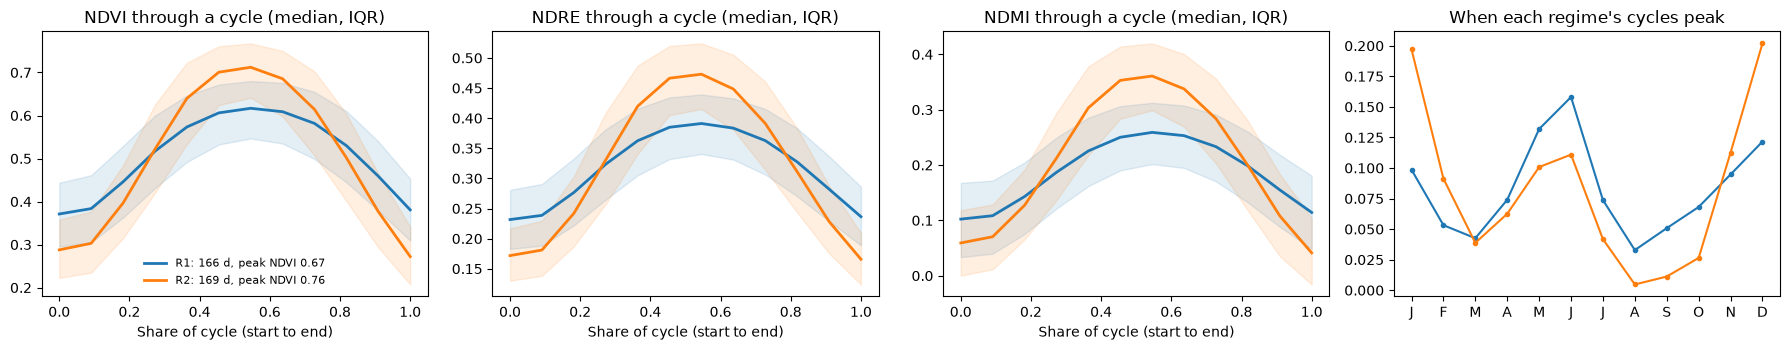

In [6]:
cropland_pixels = np.nonzero(pixel_summary["land"].to_numpy() == "active cropland")[0]
crop_cycles_mask = cycles["pixel"].isin(cropland_pixels).to_numpy()
regime_cycles = cycles[crop_cycles_mask].reset_index(drop=True)
regime_curves = cycle_curves[crop_cycles_mask]
cycle_scaler = StandardScaler().fit(regime_cycles[CYCLE_FEATURES])
Zc = cycle_scaler.transform(regime_cycles[CYCLE_FEATURES])
regime_model, regime_id = choose_kmeans(Zc, range(2, 9), "Cropping regimes")
regime_cycles["regime_id"] = regime_id
profile = regime_cycles.groupby("regime_id").agg(
    cycles=("pixel", "size"), duration_days=("duration_days", "median"), greenup_days=("greenup_days", "median"),
    NDVI_peak=("NDVI_peak", "median"), NDVI_rise=("NDVI_rise", "median"), NDRE_peak=("NDRE_peak", "median"),
    NDMI_peak=("NDMI_peak", "median"), B5_peak=("B5_peak", "median"), B11_rise=("B11_rise", "median"))
order = profile.sort_values("duration_days").index
REGIMES = {old: f"R{new + 1}: {profile.loc[old, 'duration_days']:.0f} d, peak NDVI {profile.loc[old, 'NDVI_peak']:.2f}"
           for new, old in enumerate(order)}
regime_cycles["regime"] = regime_cycles["regime_id"].map(REGIMES)
profile.index = profile.index.map(REGIMES)
profile = profile.loc[[REGIMES[i] for i in order]]
profile.to_csv(OUTPUT / "regime_profiles.csv")
display(profile)
REGIME_NAMES = list(profile.index)
REGIME_COLORS = dict(zip(REGIME_NAMES, plt.cm.tab10(np.arange(len(REGIME_NAMES)))))

figure, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for axis, (v, var) in zip(axes[:3], enumerate(CURVE_VARS)):
    for name in REGIME_NAMES:
        mask = (regime_cycles["regime"] == name).to_numpy()
        curves = regime_curves[mask, :, v]
        x = np.linspace(0, 1, CURVE_POINTS)
        axis.plot(x, np.median(curves, 0), color=REGIME_COLORS[name], lw=2, label=name)
        axis.fill_between(x, *np.percentile(curves, [25, 75], 0), color=REGIME_COLORS[name], alpha=0.12)
    axis.set_title(f"{var} through a cycle (median, IQR)")
    axis.set_xlabel("Share of cycle (start to end)")
months_table = pd.crosstab(regime_cycles["peak_month"], regime_cycles["regime"], normalize="columns").reindex(range(1, 13), fill_value=0)
for name in REGIME_NAMES:
    axes[3].plot(months_table.index, months_table[name], "-o", ms=3, color=REGIME_COLORS[name])
axes[3].set_xticks(range(1, 13), list("JFMAMJJASOND"))
axes[3].set_title("When each regime's cycles peak")
axes[0].legend(frameon=False, fontsize=8)
figure.tight_layout()
figure.savefig(FIGURES / "regime_signatures.png", dpi=150)
plt.show()

## 5. Cycles per year, regime and peak season

For each active cropland pixel: cycles per year, the most common regime and the share of cycles in it (below 50% is "mixed"), and the season with the most cycle peaks (Dec-Feb, Mar-May, Jun-Aug or Sep-Nov).

The detected cycles per year are compared with the calendars: Area 2 has 3 crops per year (potato, cabbage, carrot), B1 has 2 (cabbage, carrot) and Area 3 has cabbage all year (about 3). Lettuce (B2) and seedbeds (Area 5) are expected to be undercounted because they are shorter than the 2-month minimum.

The sensitivity table repeats the count with a lower peak threshold (0.10) and without smoothing. If the counts are still below the calendar, consecutive crops cannot be separated at half-month resolution and one cycle can include more than one crop.

In [7]:
SEASON_NAMES = ["Dec-Feb", "Mar-May", "Jun-Aug", "Sep-Nov"]
season_of = {12: 0, 1: 0, 2: 0, 3: 1, 4: 1, 5: 1, 6: 2, 7: 2, 8: 2, 9: 3, 10: 3, 11: 3}
regime_cycles["season"] = regime_cycles["peak_month"].map(season_of)
dominant = regime_cycles.groupby("pixel")["regime"].agg(lambda s: s.value_counts().index[0])
consistency = regime_cycles.groupby("pixel")["regime"].agg(lambda s: s.value_counts(normalize=True).iloc[0])
main_season = regime_cycles.groupby("pixel")["season"].agg(lambda s: s.value_counts().index[0])
pixel_summary["dominant_regime"] = pd.Series(dominant).reindex(range(N)).to_numpy()
pixel_summary["regime_consistency"] = pd.Series(consistency).reindex(range(N)).to_numpy()
pixel_summary["main_peak_season"] = pd.Series(main_season).reindex(range(N)).to_numpy()
pixel_summary.loc[pixel_summary["regime_consistency"] < 0.5, "dominant_regime"] = "mixed"

expected = {"Area 2": "3 (potato, cabbage, carrot)", "B1": "2 (cabbage, carrot)", "Area 3": "~3 (year-round cabbage)",
            "B2": "4+ (lettuce; faster than detectable)", "Area 5": "irregular (seedbeds, ornamentals)",
            "Area 1": "2-3 (multi-crop calendar)", "Area 4": "2-3 (multi-crop calendar)", "Polygon 3": "no calendar"}
count_check = []
for name, mask in interiors.items():
    inside = mask[pixel_summary["row"], pixel_summary["col"]]
    if not inside.sum():
        continue
    part = pixel_summary[inside]
    regimes = regime_cycles[regime_cycles["pixel"].isin(np.nonzero(inside)[0])]["regime"].value_counts(normalize=True)
    count_check.append({"area": name, "calendar_crops_per_year": expected.get(name, "-"),
                        "detected_cycles_per_year_median": part["cycles_per_year"].median(),
                        "active_cropland_share": (part["land"] == "active cropland").mean(),
                        "most_common_regime": regimes.index[0] if len(regimes) else "-",
                        "its_share": regimes.iloc[0] if len(regimes) else np.nan})
count_check = pd.DataFrame(count_check).set_index("area")
count_check.to_csv(OUTPUT / "kml_area_check.csv")
display(count_check)

# sensitivity of cycle counts to the peak threshold and smoothing
sensitivity = []
check_areas = ["B1", "Area 2", "Area 3"]
for prominence in (0.10, 0.15):
    for smoothing in (True, False):
        for area in check_areas:
            inside = np.nonzero(interiors[area][pixel_summary["row"], pixel_summary["col"]])[0]
            raw_ndvi = series[:, inside, VARS.index("NDVI")]
            ndvi_matrix = smooth(raw_ndvi) if smoothing else pd.DataFrame(raw_ndvi).interpolate(limit=2, limit_area="inside", axis=0).to_numpy()
            counts, durations = [], []
            for k, j in enumerate(inside):
                found = cycle_bounds(ndvi_matrix[:, k], clear[:, j], prominence)
                counts.append(len(found) / years_covered[j])
                durations += [days(a, c) for a, _, c in found]
            sensitivity.append({"peak_prominence": prominence, "smoothing": smoothing, "area": area, "calendar_crops_per_year": expected[area],
                                "cycles_per_year_median": np.median(counts), "cycle_days_median": np.median(durations) if durations else np.nan})
sensitivity = pd.DataFrame(sensitivity)
sensitivity.to_csv(OUTPUT / "detection_sensitivity.csv", index=False)
display(sensitivity.pivot_table(index=["peak_prominence", "smoothing"], columns="area", values=["cycles_per_year_median", "cycle_days_median"]))

,calendar_crops_per_year,detected_cycles_per_year_median,active_cropland_share,most_common_regime,its_share
area,,,,,
B2,4+ (lettuce; faster than detectable),1.806,0.981,"R1: 166 d, peak NDVI 0.67",0.511
B1,"2 (cabbage, carrot)",1.677,0.978,"R1: 166 d, peak NDVI 0.67",0.550
Polygon 3,no calendar,1.290,0.835,"R1: 166 d, peak NDVI 0.67",0.552
Area 1,2-3 (multi-crop calendar),1.419,0.822,"R1: 166 d, peak NDVI 0.67",0.538
Area 2,"3 (potato, cabbage, carrot)",1.290,0.941,"R2: 169 d, peak NDVI 0.76",0.548
Area 3,~3 (year-round cabbage),1.677,1.000,"R2: 169 d, peak NDVI 0.76",0.704
Area 4,2-3 (multi-crop calendar),1.161,0.722,"R1: 166 d, peak NDVI 0.67",0.551
Area 5,"irregular (seedbeds, ornamentals)",0.516,0.000,-,NaN


cycle_days_median               cycles_per_year_median              
area                                 Area 2 Area 3     B1                 Area 2 Area 3     B1
peak_prominence smoothing                                                                     
0.10            False                 138.0  152.0  122.0                  1.677  2.065  2.065
                True                  167.0  168.0  138.0                  1.419  1.806  1.806
0.15            False                 153.0  153.0  136.0                  1.548  1.935  1.935
                True                  167.0  168.0  151.0                  1.290  1.677  1.677

## 6. Maps

Land activity, cycles per year, regime and main peak season, with the KML areas outlined. Each map is also saved as a GeoTIFF.

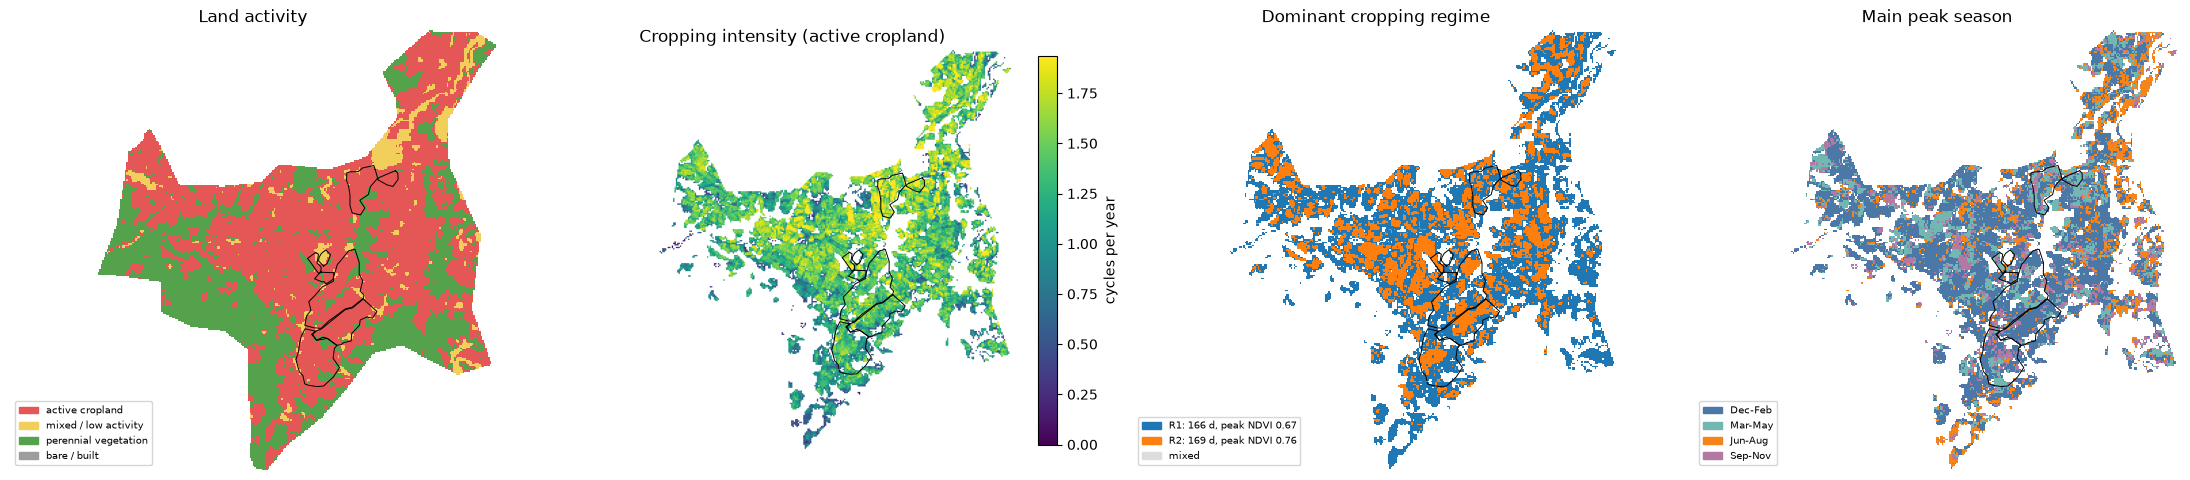

In [8]:
def to_grid_map(values, fill=np.nan):
    grid = np.full((H, W), fill, dtype="float32")
    grid[pixel_summary["row"], pixel_summary["col"]] = values
    return grid


def outline(axis):
    for name, geom in polygons["grid_geometry"].items():
        xs, ys = geom.exterior.xy
        px = [~WINDOW_TRANSFORM * (x, y) for x, y in zip(xs, ys)]
        axis.plot([p[0] for p in px], [p[1] for p in px], color="black", lw=0.7)


def save_geotiff(name, grid, description):
    with rasterio.open(OUTPUT / f"{name}.tif", "w", driver="GTiff", height=H, width=W, count=1, dtype="float32",
                       crs=GRID_CRS, transform=WINDOW_TRANSFORM, nodata=np.nan) as destination:
        destination.write(grid.astype("float32"), 1)
        destination.update_tags(description=description)


land_code = to_grid_map(pd.Series(pixel_summary["land"]).map({c: i for i, c in enumerate(LAND_CLASSES)}).to_numpy())
cropland = pixel_summary["land"].to_numpy() == "active cropland"
intensity = to_grid_map(np.where(cropland, pixel_summary["cycles_per_year"], np.nan))
regime_order = REGIME_NAMES + ["mixed"]
regime_code = to_grid_map(np.where(cropland, pixel_summary["dominant_regime"].map({r: i for i, r in enumerate(regime_order)}), np.nan))
season_code = to_grid_map(np.where(cropland, pixel_summary["main_peak_season"], np.nan))
save_geotiff("land_activity", land_code, "codes: " + ", ".join(f"{i}={c}" for i, c in enumerate(LAND_CLASSES)))
save_geotiff("cycles_per_year", intensity, "growth cycles per year, active cropland only")
save_geotiff("dominant_regime", regime_code, "codes: " + ", ".join(f"{i}={c}" for i, c in enumerate(regime_order)))
save_geotiff("main_peak_season", season_code, "codes: " + ", ".join(f"{i}={c}" for i, c in enumerate(SEASON_NAMES)))

figure, axes = plt.subplots(1, 4, figsize=(22, 6))
panels = [
    (land_code, ListedColormap(LAND_COLORS), LAND_CLASSES, "Land activity"),
    (regime_code, ListedColormap([REGIME_COLORS[r] for r in REGIME_NAMES] + ["#DDDDDD"]), regime_order, "Dominant cropping regime"),
    (season_code, ListedColormap(["#4C78A8", "#72B7B2", "#F58518", "#B279A2"]), SEASON_NAMES, "Main peak season"),
]
for axis, (grid, cmap, names, title) in zip([axes[0], axes[2], axes[3]], panels):
    axis.imshow(grid, cmap=cmap, vmin=-0.5, vmax=len(names) - 0.5, interpolation="nearest")
    axis.legend([plt.Rectangle((0, 0), 1, 1, color=cmap(i)) for i in range(len(names))], names, loc="lower left", fontsize=7, frameon=True)
    axis.set_title(title)
image = axes[1].imshow(intensity, cmap="viridis", vmin=0, vmax=np.nanpercentile(intensity, 98))
figure.colorbar(image, ax=axes[1], fraction=0.04, label="cycles per year")
axes[1].set_title("Cropping intensity (active cropland)")
for axis in axes:
    outline(axis)
    axis.axis("off")
figure.tight_layout()
figure.savefig(FIGURES / "unsupervised_maps.png", dpi=150)
plt.show()

## 7. Growth phase in 2025

For early April, August and December 2025, each active cropland pixel is classed as green-up (between cycle start and peak), peak (within one half-month of the peak), senescence (after the peak) or no detected cycle (fallow or a crop too short to detect).

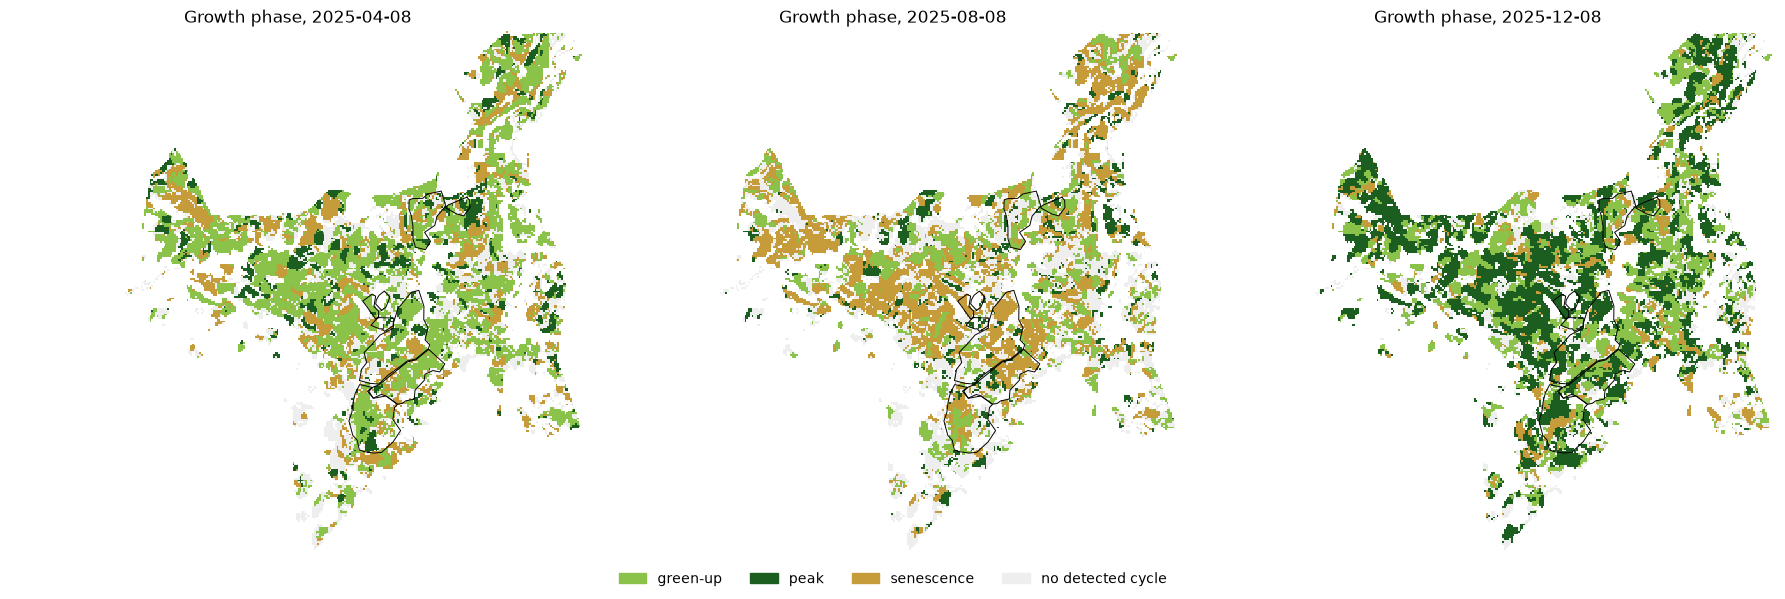

,green-up,peak,senescence,no detected cycle
date,,,,
2025-04-08,43%,12%,20%,25%
2025-08-08,20%,9%,34%,37%
2025-12-08,28%,43%,10%,18%


In [9]:
PHASES = ["green-up", "peak", "senescence", "no detected cycle"]
PHASE_COLORS = ["#8BC34A", "#1B5E20", "#C69C3A", "#EEEEEE"]
phase_dates = [i for i, (y, m, h) in enumerate(SLOTS) if y == 2025 and h == 1 and m in (4, 8, 12)]
figure, axes = plt.subplots(1, len(phase_dates), figsize=(6 * len(phase_dates), 5.8))
phase_records = []
for axis, slot in zip(axes, phase_dates):
    phase = np.full(N, 3.0)
    active = regime_cycles[(regime_cycles["start_slot"] <= slot) & (regime_cycles["end_slot"] >= slot)]
    for _, cycle in active.iterrows():
        if abs(slot - cycle["peak_slot"]) <= 1:
            phase[cycle["pixel"]] = 1
        else:
            phase[cycle["pixel"]] = 0 if slot < cycle["peak_slot"] else 2
    phase = np.where(cropland, phase, np.nan)
    grid = to_grid_map(phase)
    label = SLOT_DATE[slot].strftime("%Y-%m-%d")
    save_geotiff(f"growth_phase_{label}", grid, "codes: " + ", ".join(f"{i}={p}" for i, p in enumerate(PHASES)))
    axis.imshow(grid, cmap=ListedColormap(PHASE_COLORS), vmin=-0.5, vmax=3.5, interpolation="nearest")
    outline(axis)
    axis.set_title(f"Growth phase, {label}")
    axis.axis("off")
    shares = pd.Series(phase[cropland]).map(dict(enumerate(PHASES))).value_counts(normalize=True)
    phase_records.append({"date": label, **{p: shares.get(p, 0.0) for p in PHASES}})
figure.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in PHASE_COLORS], PHASES, loc="lower center", ncol=4, frameon=False)
figure.tight_layout(rect=(0, 0.05, 1, 1))
figure.savefig(FIGURES / "growth_phase_2025.png", dpi=150)
plt.show()
display(pd.DataFrame(phase_records).set_index("date").style.format("{:.0%}"))

## 8. Regimes in the KML areas

For the areas with calendars, this table shows which regimes their cycles fall in, next to the crop the calendar gives for the peak month. It is only for description; the regimes are not given crop names here, because notebook 08 showed that calendar crops do not transfer to other fields.

In [10]:
CALENDAR_AT_PEAK = {  # crop named in each KML calendar for that month
    "B1": {1: "cabbage", 2: "cabbage", 3: "carrot", 4: "carrot", 5: "carrot", 6: "carrot"},
    "Area 2": {3: "potato", 4: "potato", 5: "potato", 6: "potato", 7: "cabbage", 8: "cabbage", 9: "cabbage", 10: "cabbage",
               11: "carrot", 12: "carrot", 1: "carrot", 2: "carrot"},
    "Area 3": {m: "cabbage" for m in range(1, 13)},
}
rows = []
for area, calendar in CALENDAR_AT_PEAK.items():
    inside = interiors[area][pixel_summary["row"], pixel_summary["col"]]
    part = regime_cycles[regime_cycles["pixel"].isin(np.nonzero(inside)[0])]
    rows.append(part.assign(area=area, calendar_crop=part["peak_month"].map(calendar).fillna("not stated")))
described = pd.concat(rows)
table = pd.crosstab([described["area"], described["calendar_crop"]], described["regime"], normalize="index")
display(table.style.format("{:.0%}").background_gradient(axis=None, cmap="Blues"))

summary = {
    "pixels": int(N), "growth_cycles": int(len(cycles)),
    "land_activity_k": int(land_model.n_clusters), "regimes_k": int(regime_model.n_clusters),
    "kml_crop_area_active_cropland_share": round(float(np.average(area_check["active cropland"], weights=area_check["pixels"])), 3),
    "namria_noncrop_left_out_of_cropland_share": round(NAMRIA_NONCROP_EXCLUDED, 3),
    "active_cropland_pixels": int(cropland.sum()), "regimes": REGIME_NAMES,
    "crop_names": "not assigned",
}
(OUTPUT / "summary.json").write_text(json.dumps(summary, indent=2))
for key, value in summary.items():
    print(f"{key}: {value}")

pixels: 36006
growth_cycles: 281394
land_activity_k: 3
regimes_k: 2
kml_crop_area_active_cropland_share: 0.861
namria_noncrop_left_out_of_cropland_share: 0.921
active_cropland_pixels: 21125
regimes: ['R1: 166 d, peak NDVI 0.67', 'R2: 169 d, peak NDVI 0.76']
crop_names: not assigned
